In [1]:
import numpy as np
import pandas as pd
import xsim
import xtools as xt
import matplotlib.pyplot as plt
from pyqubo import Array, Constraint
from openjij import SQASampler, SASampler
from typing import Callable, Dict, List

from atm.flight.generator import ScenarioGenerator, Scenario
from atm.optimizer.objective import get_obj_single_runway, calc_assign_time
from atm.separation import recat, faa

In [2]:
cf = xt.Config(dict(
    num=5,
    scenario=dict(
        interval=60,
        window=200,
        mode="mix",
        standard="recat",
        seed=0,
    ),
    penalty_coef=10,
))
sep = recat.TBS if cf.scenario.standard == "recat" else faa.TBS

In [3]:
def generate_scenario_and_obj(config, seed=None):
    if seed is not None:
        if hasattr(config, "config"):
            config.seed = seed
        else:
            config.set("seed", seed)
    gen = ScenarioGenerator(config.scenario)
    vols = gen(config.num)
    obj = get_obj_single_runway(vols, sep, penalty_coef=config.penalty_coef)
    return vols, obj

In [4]:
vols, obj = generate_scenario_and_obj(cf)
type(vols)

atm.flight.scenario.Scenario

In [5]:
class SequenceMetropolisHastings:
    
    def __init__(
            self,
            vols: Scenario,
            objective: Callable,
            temp: float = 1.,
            seed: int = None
    ):
        self.nv = len(vols)
        self.nx = len(vols)
        self.vols = vols
        self.obj = objective
        self.T = temp
        
        # seeding
        self._seed: int = None
        self._rng: np.random.Generator = None
        self.seed(seed)
        
        # sate holders
        self.x_best = None
        self.e_best = None
        
        self._logger: xsim.Logger = None
        
    def seed(self, seed: int = None) -> int:
        if seed is None:
            seed = np.random.randint(0, 1e+8)
        self._seed = seed
        self._rng = np.random.default_rng(seed)
        return seed
    
    def evaluate(self, x) -> float:
        return self.obj(x)
    
    def initialize(self):
        self._logger = xsim.Logger()
        self.seed(self._seed)
    
    def _initial_sampling(self, x_init = None):
        if x_init is None:
            return np.arange(self.nx)
        
        if isinstance(x_init, str) and x_init == "random":
            return self._rng.choice(
                np.arrange(self.nx),
                self.nx, replace=False
            )
        elif x_init == "default":
            return np.arange(self.nx)
        
        return np.asarray(x_init)
    
    def log(self, x, e):
        self._logger.store(**dict(
            step=len(self._logger),
            xp=x, ep=e,
            x_best=self.x_best,
            e_best=self.e_best,
        )).flush()
    
    def sample(self, xc, step=None):
        idx1, idx2 = self._rng.choice(np.arange(self.nv), 2, replace=False)
        xc = np.squeeze(xc)
        xp = xc.copy()
        xp[idx1] = xc[idx2]
        xp[idx2] = xc[idx1]
        return xp
    
    def prob(self, e):
        return np.exp(-1 * e / self.T)
    
    def calc_accept_prob(self, ec, ep):
        de = ep - ec
        if de < 0:
            return 1
        r = self.prob(de)
        return r
    
    def select_best_solution(self, xp, ep):
        if ep <= self.e_best:
            self.x_best = xp
            self.e_best = ep
    
    @property
    def result(self):
        ret = xsim.Retriever(self._logger)
        res = dict(
            step=ret.step(),
            e_proposed=ret.ep(),
            e_best=ret.e_best(),
        )
        
        res_x_prop = {
            f"x_proposed_{i}": ret.xp(idx=i)
            for i in range(len(self.x_best))
        }
        res_x_best = {
            f"x_best_{i}": ret.x_best(idx=i)
            for i in range(len(self.x_best))
        }
        res = pd.DataFrame(dict(**res, **res_x_prop, **res_x_best))
        return res
    
    def optimize(self, num_iter: int, x_init: np.ndarray = None):
        self.initialize()
        
        # initial sampling and evaluate
        self.x_best = xc = self._initial_sampling(x_init)
        self.e_best = ec = self.evaluate(xc)
        self.log(xc, ec)
        
        for step in range(1, num_iter):
            # sample and evaluation
            xp = self.sample(xc, step)
            ep = self.evaluate(xp)
            
            # stochastic accepting
            r = self.calc_accept_prob(ec, ep)
            if r > self._rng.random():
                
                xc = xp
                ec = ep
            
            # select best solution
            self.select_best_solution(xp, ep)
            self.log(xp, ep)
            
        return self.result

<AxesSubplot:xlabel='step'>

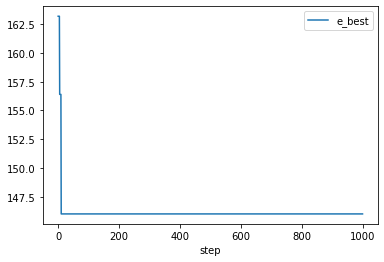

In [6]:
algo = SequenceMetropolisHastings(vols, obj, temp=1)
res = algo.optimize(num_iter=1000)
res.plot("step", "e_best")

In [8]:
class SwapMetropolisHastings:
    
    def __init__(self, margins, sampler=SASampler):
        self._step = 0
        self._margins = margins
        self._sampler = sampler()
    
    def _get_separation_function(self):
        def sf(item1, item2):
            return self._margins(item1, item2)
        return sf
    
    def _get_step(self, step=None):
        return step if step is not None else self._step
    
    def retrieve_target_items(self, original_items, step=None):
        step = self._get_step(step)
        shift_by_step = (step - 1) % 2
        head_item = original_items[:shift_by_step]
        retr_items = original_items[shift_by_step:]
        
        len_retr_items = len(retr_items)
        shift_by_len = len_retr_items % 2
        tail_item = original_items[len_retr_items - shift_by_len:]
        retr_items = retr_items[:len_retr_items - shift_by_len]
        
        return head_item, retr_items, tail_item
    
    def make_pairs(self, target_x):
        target_x = np.asarray(target_x)
        return target_x.reshape((-1, 2))
    
    def build_cost(self, item_pairs):
        ks = item_pairs
        S = self._get_separation_function()
        
        # intra-pair cost
        xs = Array.create("x", shape=len(item_pairs), vartype="BINARY")
        e_in = Constraint(sum([
            S(vol1, vol2) * (1 - x) + S(vol2, vol1) * x
            for (vol1, vol2), x in zip(ks, xs)
        ]), "inner")
        e_total = e_in
        
        # convert iterator of var to list
        if len(xs) > 1:
            lxs = list(xs)
            # inter-pair cost
            e_ex = Constraint(sum([
                (S(j2, k2) - S(j2, k1)) * xk + (S(j1, k1) - S(j2, k1)) * xk + (S(j1, k2) - S(j2, k1)) * xj * xk
                for (j1, j2), (k1, k2), xj, xk in zip(ks[:-1], ks[1:], lxs[:-1], lxs[1:])
            ]), "external")
            
            e_total = e_total + e_ex
        
        return e_total
    
    def build_qubo(self, item_pairs):
        cost = self.build_cost(item_pairs)
        model = cost.compile()
        return model.to_qubo()
    
    def sample_first_from_qubo(self, qubo):
        sampleset = self._sampler.sample_qubo(qubo)
        return sampleset.first
        
        
    def sample(self, x, step=None):
        # initialize queue
        orig_items = [v for v in x]
        
        # retrieve target items and
        # make pairs
        head_item, target_items, tail_item = self.retrieve_target_items(orig_items, step=step)
        paired_items = self.make_pairs(target_items)
        
        # sample from qubo
        qubo, bias = self.build_qubo(paired_items)
        first = self.sample_first_from_qubo(qubo)
        sampled_items = np.squeeze([
            paired_item if xk == 0 else paired_item[::-1]
            for paired_item, xk in zip(paired_items, first.sample.values())
        ]).flatten()
        
        solution = np.hstack((head_item, sampled_items, tail_item))
        
        ep = first.energy + bias
        eb = bias
        
        return solution, ep, eb
    
step = 1

algo = SwapMetropolisHastings(sep)
xp  = algo.sample(vols, step=step)

In [9]:
x_orig = np.arange(6)
step = 1

algo = SwapMetropolisHastings(sep)
xsampled = algo.sample(vols, step=step)
print(vols.to_dataframe())
xsampled
# hi, target_items, ti = algo.retrieve_target_items(x_orig)
# print(target_items)
# paired_items = algo.make_pairs(target_items)
# paired_items

      code  ready  due category operation
0  VOL0001     35  235        A         D
1  VOL0002     55  255        A         A
2  VOL0003     85  285        E         A
3  VOL0004    121  321        C         D
4  VOL0005    172  372        B         A


(array([<atm.flight.flight.Flight object at 0x1376e56d0>,
        <atm.flight.flight.Flight object at 0x1376e5df0>], dtype=object),
 147.0,
 159.0)

In [ ]:
res.plot("step", "e_best")

## How to make pair with various length queues

Length of queue is $L$.
Step is $s$.

1. L < 2
No-pair


2. L >= 2
2.1. L % 2 = 0 (even)


2.2. L % 2 = 1 (odd)

In [ ]:
xx = np.arange(5)
step = 1
sbs = (step - 1) % 2

print("sbs:", sbs)
xxh = xx[:sbs]
xxr = xx[sbs:]
print("retrieved head :", xxh)
print("retrieved queue:", xxr)

lr = len(xxr)
sbl = lr % 2
xxt = xxr[lr - sbl:]
xxr = xxr[:lr - sbl]
print("retrieved tail :", xxt)
print("retrieved queue:", xxr)

ks = [
    [xxr[2 * i], xxr[2 * i + 1]]
    for i in range(lr // 2)
]
print("pairs:", ks)

In [ ]:
xs = sum(ks, [])
print("xs:", xs)
xs = np.hstack([xxh, xs, xxt])
print("xs:", xs)